### Imports

In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
%pip install -U importlib_resources

In [3]:
(train_ds, val_ds, test_ds), ds_info  = tfds.load('food101', split=['train[:80%]', 'train[80%:]', 'validation'], as_supervised=True, with_info=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.BL1A6T_2.0.0/food101-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/food101/incomplete.BL1A6T_2.0.0/food101-validation.tfrecord-[0-9][0-9][0-9…

Dataset food101 downloaded and prepared to /root/tensorflow_datasets/food101/2.0.0. Subsequent calls will reuse this data.


In [4]:
train_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>

### Preprocessing

In [5]:
num_classes = ds_info.features['label'].num_classes
class_names = ds_info.features['label'].names
len(class_names)

101

In [6]:
import json
json.dump(class_names, open('class_names.json', 'w'))

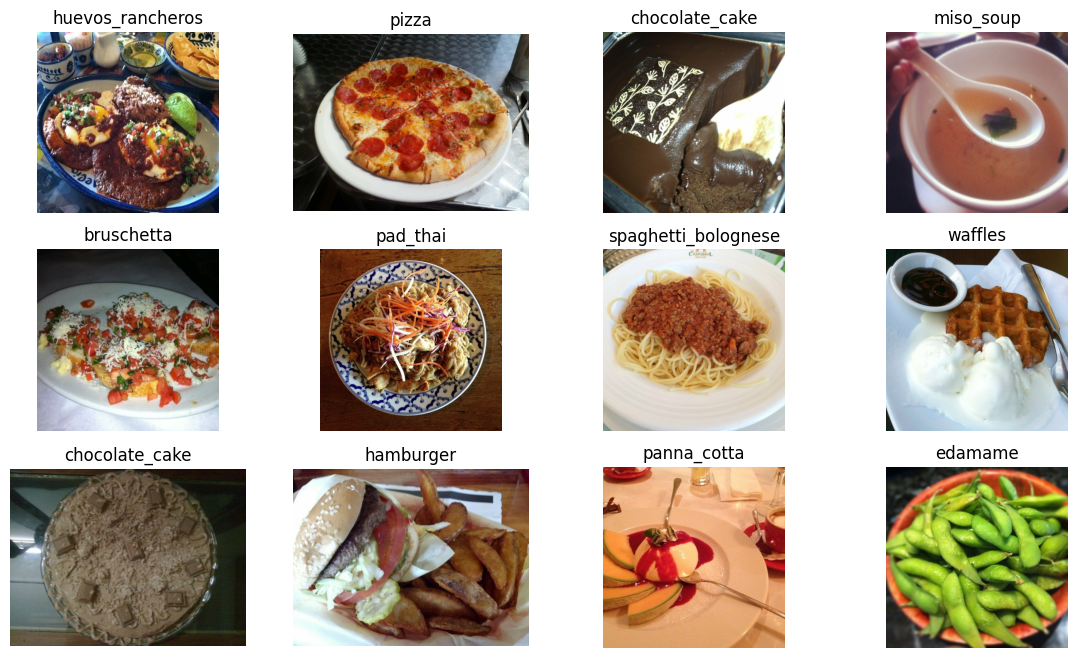

In [7]:
plt.figure(figsize=(14,8))
for i, (image, label) in enumerate(train_ds.take(12)):
    plt.subplot(3,4,i+1)
    plt.imshow(image)
    plt.title(class_names[label])
    plt.axis('off')
plt.show()

In [8]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return tf.cast(image, tf.float32), label     # keep 0-255

train_data = (train_ds.map(preprocess, AUTOTUNE)
              .shuffle(1000)
              .batch(BATCH_SIZE)
              .prefetch(AUTOTUNE))
val_data  = val_ds.map(preprocess, AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_data = test_ds.map(preprocess, AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [9]:
for image, label in train_ds.take(5):
    print(image.shape, label.shape)
    print(label)

(512, 512, 3) ()
tf.Tensor(56, shape=(), dtype=int64)
(384, 512, 3) ()
tf.Tensor(76, shape=(), dtype=int64)
(512, 512, 3) ()
tf.Tensor(21, shape=(), dtype=int64)
(512, 512, 3) ()
tf.Tensor(64, shape=(), dtype=int64)
(512, 512, 3) ()
tf.Tensor(10, shape=(), dtype=int64)


In [10]:
for image, label in train_data.take(5):
    print(image.shape, label.shape)
    print(label)


(32, 224, 224, 3) (32,)
tf.Tensor(
[ 6  5 33 20 73 11 76 69 41 30 24 49 68 93 91 23 97 58 21 62 39 86 52 88
 13 97 19 32 59 57 13 21], shape=(32,), dtype=int64)
(32, 224, 224, 3) (32,)
tf.Tensor(
[81 40 83  1 14 73 63 79 58 67 23 86  1  9 63 11 22 37 24 60 16 17 49 56
 22 29 44 72 42 23 14 41], shape=(32,), dtype=int64)
(32, 224, 224, 3) (32,)
tf.Tensor(
[55 22 76 87 48 65  4 67 76 86 40 34  9 56 22  2 35 29  3 76 51  8 14 36
  7 14 83 57 40 18 74 22], shape=(32,), dtype=int64)
(32, 224, 224, 3) (32,)
tf.Tensor(
[ 19  36 100  54   5  74   3   0  22  29  19  73  37  47  76  81  36  38
  61  80  10  41  31  85  43  45   4   2  57   4  48  78], shape=(32,), dtype=int64)
(32, 224, 224, 3) (32,)
tf.Tensor(
[ 51  36  64  10   1  57  52  42  25  81  86  53 100  27  84  10  37  72
 100  93   5  77  91   9  15   4  97  94  18  98  84  82], shape=(32,), dtype=int64)


### Augmentation

In [11]:
augment = tf.keras.models.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
], name = 'augmentation')

In [12]:
base = tf.keras.applications.EfficientNetB0(include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3), weights='imagenet')
base

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


<Functional name=efficientnetb0, built=True>

In [ ]:
base.trainable = False  # freeze for phase 1

### Building Model

In [ ]:
inputs = tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augment(inputs)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
output = tf.keras.layers.Dense(101, activation='softmax')(x)
model = tf.keras.models.Model(inputs, output)

### Compile

In [19]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
              metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="Top5")])

In [20]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,178,952 (15.94 MB)

 Trainable params: 129,381 (505.39 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

### Phase 1 training (train only the new top layer)

In [17]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint('best_model.keras', save_best_only=True, monitor='val_loss'),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.1, patience=2)
]
history = model.fit(train_data, validation_data=val_data, epochs=5, callbacks=callbacks)

Epoch 1/5
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 220s 107ms/step - Top5: 0.7319 - accuracy: 0.4646 - loss: 2.2277 - val_Top5: 0.8477 - val_accuracy: 0.6068 - val_loss: 1.5390 - learning_rate: 0.0010
Epoch 2/5
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 203s 106ms/step - Top5: 0.8180 - accuracy: 0.5678 - loss: 1.6967 - val_Top5: 0.8622 - val_accuracy: 0.6349 - val_loss: 1.4187 - learning_rate: 0.0010
Epoch 3/5
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 207s 108ms/step - Top5: 0.8329 - accuracy: 0.5896 - loss: 1.5962 - val_Top5: 0.8710 - val_accuracy: 0.6462 - val_loss: 1.3712 - learning_rate: 0.0010
Epoch 4/5
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 207s 108ms/step - Top5: 0.8431 - accuracy: 0.6015 - loss: 1.5425 - val_Top5: 0.8745 - val_accuracy: 0.6531 - val_loss: 1.3436 - learning_rate: 0.0010
Epoch 5/5
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 210s 110ms/step - Top5: 0.8476 - accuracy: 0.6086 - loss: 1.5068 - val_Top5: 0.8762 - val_accuracy: 0.6562 - val_loss: 1.3313 - learning_rate: 0.0010


### Phase 2 fine-tuning

In [ ]:
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False          # keep BN frozen for stable fine-tuning

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy', tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='Top5')])

history2 = model.fit(train_data, validation_data=val_data, epochs=10,
                     callbacks=callbacks)

Epoch 1/10
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 240s 118ms/step - Top5: 0.8700 - accuracy: 0.6425 - loss: 1.3610 - val_Top5: 0.8828 - val_accuracy: 0.6709 - val_loss: 1.2745 - learning_rate: 1.0000e-05
Epoch 2/10
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 220s 115ms/step - Top5: 0.8780 - accuracy: 0.6562 - loss: 1.3021 - val_Top5: 0.8862 - val_accuracy: 0.6795 - val_loss: 1.2491 - learning_rate: 1.0000e-05
Epoch 3/10
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 221s 116ms/step - Top5: 0.8827 - accuracy: 0.6646 - loss: 1.2646 - val_Top5: 0.8889 - val_accuracy: 0.6840 - val_loss: 1.2313 - learning_rate: 1.0000e-05
Epoch 4/10
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 230s 121ms/step - Top5: 0.8867 - accuracy: 0.6712 - loss: 1.2381 - val_Top5: 0.8905 - val_accuracy: 0.6881 - val_loss: 1.2182 - learning_rate: 1.0000e-05
Epoch 5/10
1894/1894 ━━━━━━━━━━━━━━━━━━━━ 239s 125ms/step - Top5: 0.8883 - accuracy: 0.6790 - loss: 1.2176 - val_Top5: 0.8922 - val_accuracy: 0.6900 - val_loss: 1.2056 - learning_rate: 1.0000e-05
Epoch 6/10
1894/1894

### Training curves

In [28]:
import os
os.makedirs('results', exist_ok=True)
acc = history.history['accuracy'] + history2.history['accuracy']
vacc = history.history['val_accuracy'] + history2.history['val_accuracy']

top5 = history.history['Top5'] + history2.history['Top5']
top5v = history.history['val_Top5'] + history2.history['val_Top5']

loss = history.history['loss'] + history2.history['loss']
vloss = history.history['val_loss'] + history2.history['val_loss']
n1 = len(history.history['accuracy'])

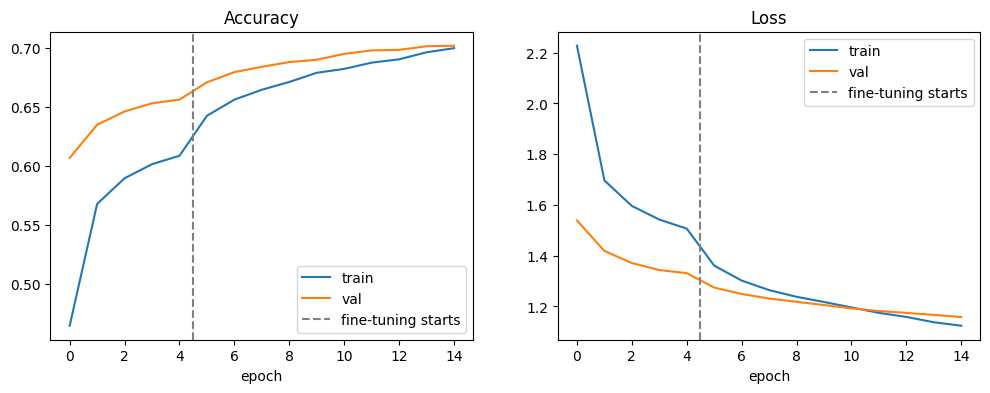

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (tr, va, t) in zip(ax, [(acc, vacc, 'Accuracy'), (loss, vloss, 'Loss')]):
    a.plot(tr, label='train'); a.plot(va, label='val')
    a.axvline(n1 - 0.5, color='gray', ls='--', label='fine-tuning starts')
    a.set_title(t)
    a.set_xlabel('epoch')
    a.legend()
plt.savefig('results/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

### Evaluate on the test set

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

test_loss, test_acc, test_top5 = model.evaluate(test_data)
print(f"Test top-1: {test_acc:.3f} | top-5: {test_top5:.3f}")

y_true = np.concatenate([y.numpy() for _, y in test_data])   # test_data is not shuffled
y_pred = model.predict(test_data).argmax(1)

report = classification_report(y_true, y_pred, target_names=class_names)
print(report)
open('results/classification_report.txt', 'w').write(report)

cm = confusion_matrix(y_true, y_pred); np.fill_diagonal(cm, 0)
for flat in np.argsort(cm.ravel())[::-1][:10]:
    t, p = np.unravel_index(flat, cm.shape)
    print(f"{class_names[t]} -> {class_names[p]}: {cm[t, p]}")


790/790 ━━━━━━━━━━━━━━━━━━━━ 71s 89ms/step - Top5: 0.9280 - accuracy: 0.7463 - loss: 0.9233
Test top-1: 0.746 | top-5: 0.928
790/790 ━━━━━━━━━━━━━━━━━━━━ 68s 83ms/step
                         precision    recall  f1-score   support

              apple_pie       0.49      0.49      0.49       250
         baby_back_ribs       0.74      0.73      0.74       250
                baklava       0.77      0.78      0.78       250
         beef_carpaccio       0.79      0.75      0.77       250
           beef_tartare       0.67      0.62      0.64       250
             beet_salad       0.60      0.64      0.62       250
               beignets       0.77      0.86      0.81       250
               bibimbap       0.87      0.88      0.87       250
          bread_pudding       0.44      0.60      0.51       250
      breakfast_burrito       0.65      0.72      0.69       250
             bruschetta       0.66      0.54      0.60       250
           caesar_salad       0.75      0.79      0

### Grad-CAM

In [31]:
def gradcam(img_path, class_idx=None):
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    arr = tf.keras.utils.img_to_array(img)[None]                  # keep 0-255
    with tf.GradientTape() as tape:
        conv = base(arr, training=False)                          # (1,7,7,1280)
        x = model.get_layer('global_average_pooling2d')(conv)
        preds = model.layers[-1](x)
        if class_idx is None: class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))                        # (1,1280)
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = (cam / (tf.reduce_max(cam) + 1e-8)).numpy()
    cam = tf.image.resize(cam[..., None], (224, 224)).numpy().squeeze()
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1); plt.imshow(img); plt.axis('off'); plt.title(class_names[class_idx])
    plt.subplot(1, 2, 2); plt.imshow(img); plt.imshow(cam, cmap='jet', alpha=0.4); plt.axis('off')
    plt.savefig('results/gradcam_example.png', dpi=150, bbox_inches='tight'); plt.show()

### Calorie estimator

In [33]:
import pandas as pd
cal_df = pd.read_csv('calories.csv').set_index('class')

def estimate(img_path, portion=1.0, threshold=0.40):
    img = tf.keras.utils.load_img(img_path, target_size=(224, 224))
    probs = model.predict(tf.keras.utils.img_to_array(img)[None], verbose=0)[0]
    top = probs.argsort()[-3:][::-1]
    if probs[top[0]] < threshold:
        return "Not sure - try a clearer photo", [(class_names[i], float(probs[i])) for i in top]
    c = class_names[top[0]]
    kcal = round(cal_df.loc[c, 'kcal'] * portion)
    return f"{c.replace('_',' ').title()}: ~{kcal} kcal ({cal_df.loc[c,'serving']} x {portion})", \
           [(class_names[i], float(probs[i])) for i in top]

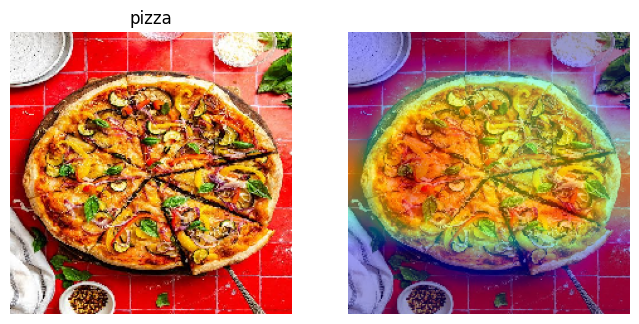

In [34]:
gradcam("sample_0.jpg")